# 06 – Exploratory data analysis of the resort and price data

**Requirement:** rich non-graphical and graphical exploratory data analysis (EDA) · **Data:** table `resorts` in `db/sci_alpi.db` (293 ski areas, one row each)

EDA means looking at the data **before** any formal model: what is missing, what is skewed, which values are extreme, which variables go together. The aim is to find patterns that were not planned and to decide which variables are fit for the models in notebook 07.

1. Overview and missing values (non-graphical)
2. One variable at a time: location, spread, shape, outliers (non-graphical)
3. Day-pass price by country (non-graphical)
4. Graphs: distribution, price by country, price against features, map, correlation heat map
5. Data provenance and quality: what is measured, what is typed by hand, what is not verified
6. Findings and checks

All numbers in the text below come from the cells above them. Columns whose status flag says *not verified* are shown only to document the problem and are **not** used for conclusions (after the Codespace run this is only the slope length of one area, Aiguille du Midi).

In [1]:
import json
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
DB_PATH = ROOT / "db" / "sci_alpi.db"
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
assert DB_PATH.exists(), "Run notebook 05_sqlite_database.ipynb first (it creates db/sci_alpi.db)."

con = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True)     # read-only
df = pd.read_sql_query("SELECT * FROM resorts", con)
pli = pd.read_sql_query("SELECT country, pli_eu27 FROM country_stats WHERE year = 2024", con).set_index("country")["pli_eu27"]
con.close()

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ORDER = ["CH", "AT", "FR", "IT"]
# Okabe-Ito colours: distinguishable also with colour-vision deficiency; each country keeps its colour in every graph
COUNTRY_COLOR = {"CH": "#D55E00", "AT": "#0072B2", "FR": "#009E73", "IT": "#CC79A7"}
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#e3e2de"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT,
                     "xtick.color": INK_SOFT, "ytick.color": INK_SOFT, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID})

status = json.loads((ROOT / "data" / "processed" / "data_status.json").read_text())
print(f"{len(df)} ski areas | status of the columns: {status}")

293 ski areas | status of the columns: {'slope_status': ['reparsed', 'unverified_old_parser'], 'hotels_status': ['openstreetmap_overpass']}


## 1. Overview and missing values

In [2]:
overview = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(1),
    "n_distinct": df.nunique(),
})
overview[overview["n_missing"] > 0]

,type,n_missing,pct_missing,n_distinct
ski_routes_km,float64,200,68.3,49
lifts_count,float64,1,0.3,62
price_day_raw,float64,2,0.7,94
alps_review_flag,str,287,98.0,6
geocode_difference_km,float64,8,2.7,49


`ski_routes_km` is empty for 200 areas because the page does not give it separately. `slope_km` (re-parsed), `lifts_count` and `hotels_4_5_star_10km` are filled; the one area without a verified slope length (Aiguille du Midi, a cable car) keeps the old slope value, flagged `unverified_old_parser`, and has no lift count. The hotel count is a **lower bound** (OpenStreetMap hotels without a star tag are not counted; median 2, maximum 82). `price_day_raw` is empty for the 2 prices typed by hand, `alps_review_flag` is filled for 6 areas that lie outside the Alps (Hochficht, Abetone, Cimone, Lelex-Crozet, Saint-Lary-Soulan, Font-Romeu), and `geocode_difference_km` is empty where only one geocode exists. **A missing value stays missing: nothing is filled with a national median.**

In [3]:
# Status flags: how reliable is each column?
flags = pd.concat({
    "price_source": df["price_source"].value_counts(),
    "slope_status": df["slope_status"].value_counts(),
    "hotels_status": df["hotels_status"].value_counts(),
    "coordinate_check": df["coordinate_check"].value_counts(),
    "scope_decision": df["scope_decision"].value_counts(),
}).rename("n_areas").to_frame()
flags

n_areas
price_source     scraped                             291
                 manual_entry                          2
slope_status     reparsed                            292
                 unverified_old_parser                 1
hotels_status    openstreetmap_overpass              293
coordinate_check verified_access_point               285
                 access_point_within_7km_review        8
scope_decision   not_individually_reviewed           260
                 outside_alps                         18
                 in_alps                              15

## 2. One variable at a time (non-graphical)

For each numeric variable: mean, median, standard deviation, quartiles, **skewness** (0 = symmetric, positive = long tail to the right) and **excess kurtosis** (0 = tails like a normal distribution, positive = heavy tails / outliers).

In [4]:
numeric = ["price_day_eur", "rating_stars", "elevation_base_m", "elevation_top_m", "dist_zurich_km", "dist_nearest_city_km"]
df["vertical_drop_m"] = df["elevation_top_m"] - df["elevation_base_m"]
numeric.insert(4, "vertical_drop_m")
desc = df[numeric].describe(percentiles=[0.25, 0.5, 0.75]).T
desc["skewness"] = df[numeric].skew()
desc["excess_kurtosis"] = df[numeric].kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skewness,excess_kurtosis
price_day_eur,293.0,64.00,16.14,24.0,51.45,66.0,74.0,121.8,-0.04,-0.17
rating_stars,293.0,3.79,0.50,2.7,3.30,3.8,4.2,4.9,0.05,-0.90
elevation_base_m,293.0,1247.19,343.19,509.0,1000.00,1229.0,1465.0,2760.0,0.58,1.43
elevation_top_m,293.0,2402.18,449.09,1338.0,2085.00,2360.0,2683.0,3899.0,0.51,0.21
vertical_drop_m,293.0,1154.99,403.80,350.0,862.00,1100.0,1398.0,2807.0,0.72,0.71
dist_zurich_km,293.0,258.31,165.93,41.4,148.40,223.6,313.4,876.2,1.89,4.05
dist_nearest_city_km,293.0,141.24,96.92,17.7,90.90,115.2,161.0,561.3,2.62,7.17


In [5]:
# Is the price normally distributed? Shapiro-Wilk (H0: normal). The log transformation is often used for prices.
sw = {}
for name, x in {"price (EUR)": df["price_day_eur"], "log(price)": np.log(df["price_day_eur"])}.items():
    w, p = stats.shapiro(x)
    sw[name] = {"W": round(w, 3), "p_value": p, "skewness": round(stats.skew(x), 2)}
pd.DataFrame(sw).T

,W,p_value,skewness
price (EUR),0.985,3.367761e-03,-0.04
log(price),0.956,8.908291e-08,-0.70


In [6]:
# Outliers by the 1.5 x IQR rule on the price
q1, q3 = df["price_day_eur"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df.loc[(df["price_day_eur"] < low) | (df["price_day_eur"] > high),
                  ["resort_name", "country", "price_day_raw", "currency", "price_day_eur", "price_source", "rating_stars"]]
print(f"IQR rule: values below {low:.1f} or above {high:.1f} EUR are flagged")
outliers.sort_values("price_day_eur", ascending=False)

IQR rule: values below 17.6 or above 107.8 EUR are flagged


,resort_name,country,price_day_raw,currency,price_day_eur,price_source,rating_stars
288,Zermatt/Breuil-Cervinia/Valtournenche – Matter...,CH,116.0,CHF,121.8,scraped,4.5


**Reading the statistics.** The price is almost symmetric (mean 64.0 EUR, median 66.0, standard deviation 16.1; skewness −0.04) and ranges from 24 to 121.8 EUR. The Shapiro–Wilk test still rejects an exact normal distribution (W = 0.985, p = 0.003), which with 293 values means only a small departure. The log transformation does **not** make the price more symmetric: log(price) is more skewed (−0.70, W = 0.956). So a log price is not justified by the shape; the model in notebook 07 must be judged by its residuals. The rating moves in steps of 0.1 and is flat (excess kurtosis −0.9). The distances are right-skewed: the distance to the nearest feeder city has skewness 2.6 and excess kurtosis 7.2, because the Pyrenees resorts are 500 to 880 km away from every feeder city. By the 1.5 × IQR rule only one price is an outlier: Zermatt–Cervinia (116 CHF, 121.8 EUR, top elevation 3,899 m), which is a real price and stays in the data.

## 3. Day-pass price by country (non-graphical)

In [7]:
by_country = df.groupby("country")["price_day_eur"].agg(n="count", mean="mean", median="median", sd="std", cv_pct=lambda x: 100 * x.std() / x.mean(),
                                                         min="min", q25=lambda x: x.quantile(.25), q75=lambda x: x.quantile(.75), max="max").loc[ORDER].round(1)
by_country

,n,mean,median,sd,cv_pct,min,q25,q75,max
country,,,,,,,,,
CH,73,72.7,70.4,15.6,21.4,41.0,64.0,80.8,121.8
AT,75,72.4,73.0,8.5,11.7,47.0,67.0,80.5,86.5
FR,71,49.3,45.0,12.9,26.2,26.0,40.8,56.4,84.2
IT,74,61.0,60.0,14.3,23.4,24.0,50.5,72.8,89.0


In [8]:
# Price relative to the national price level (PLI, EU27 = 100, year 2024): do the countries still differ?
df["pli_2024"] = df["country"].map(pli)
df["price_relative_pli"] = df["price_day_eur"] / (df["pli_2024"] / 100)
rel = df.groupby("country")[["price_day_eur", "price_relative_pli"]].mean().loc[ORDER].round(1)
rel.insert(0, "pli_2024", pli.loc[ORDER])
rel

,pli_2024,price_day_eur,price_relative_pli
country,,,
CH,184.3,72.7,39.5
AT,119.7,72.4,60.5
FR,107.9,49.3,45.7
IT,98.1,61.0,62.2


**Reading the table.** Switzerland (72.7 EUR) and Austria (72.4 EUR) have the same mean price, but not the same spread: Austrian prices are very uniform (standard deviation 8.5 EUR, coefficient of variation 11.7 %), Swiss prices are very mixed (15.6 EUR, 21.4 %). Italy follows with 61.0 EUR and France with 49.3 EUR (the most dispersed in relative terms, 26.2 %).

**Relative to the national price level** (PLI 2024, EU27 = 100: CH 184.3, AT 119.7, FR 107.9, IT 98.1) the order changes: a Swiss day pass is the cheapest in relation to what things cost in Switzerland (39.5), then France (45.7), Austria (60.5) and Italy (62.2). This is why SQ3 models the price relative to the PLI. Caution: the PLI covers all consumer goods, it is from 2024 while the list prices are from 2026, and each country has only one PLI value, so the PLI cannot be separated from other country differences.

## 4. Graphs

### 4.1 Distribution of the price

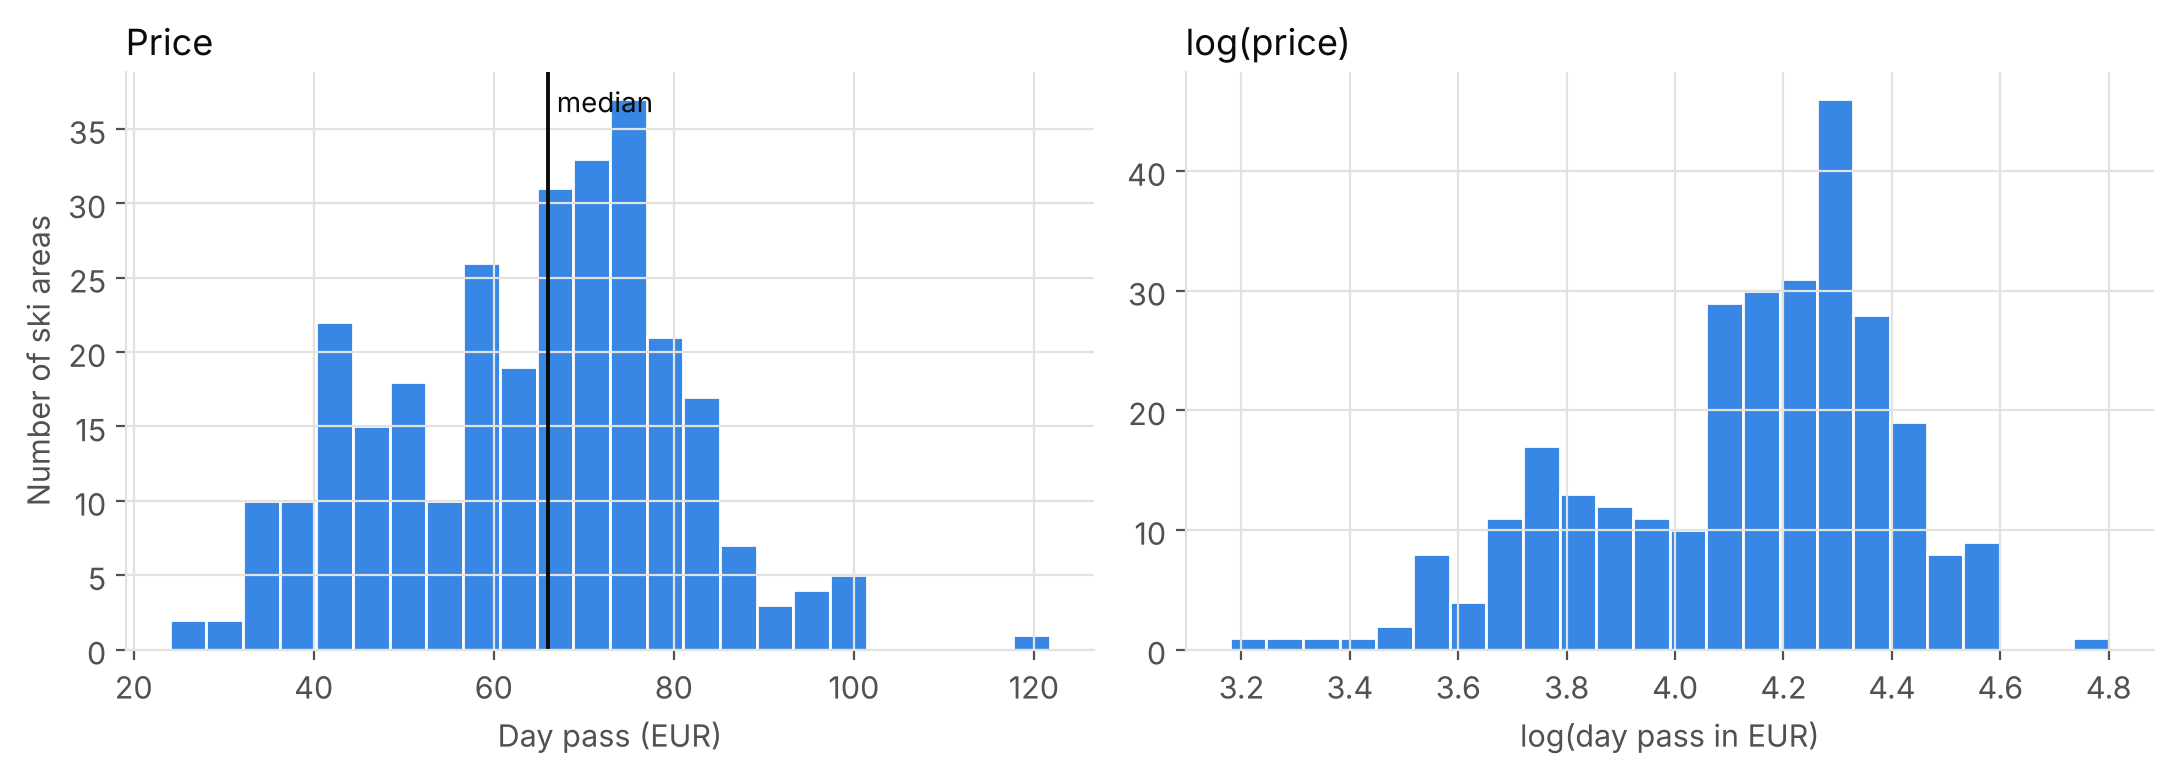

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["price_day_eur"], bins=24, color="#3987e5", edgecolor="white")
axes[0].axvline(df["price_day_eur"].median(), color=INK, linewidth=1.4)
axes[0].text(df["price_day_eur"].median() + 1, axes[0].get_ylim()[1] * 0.93, "median", color=INK, fontsize=10)
axes[0].set_xlabel("Day pass (EUR)"); axes[0].set_ylabel("Number of ski areas")
axes[0].set_title("Price", loc="left", fontsize=13, color=INK)
axes[1].hist(np.log(df["price_day_eur"]), bins=24, color="#3987e5", edgecolor="white")
axes[1].set_xlabel("log(day pass in EUR)")
axes[1].set_title("log(price)", loc="left", fontsize=13, color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_price_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.2 Price by country (every ski area is one dot)

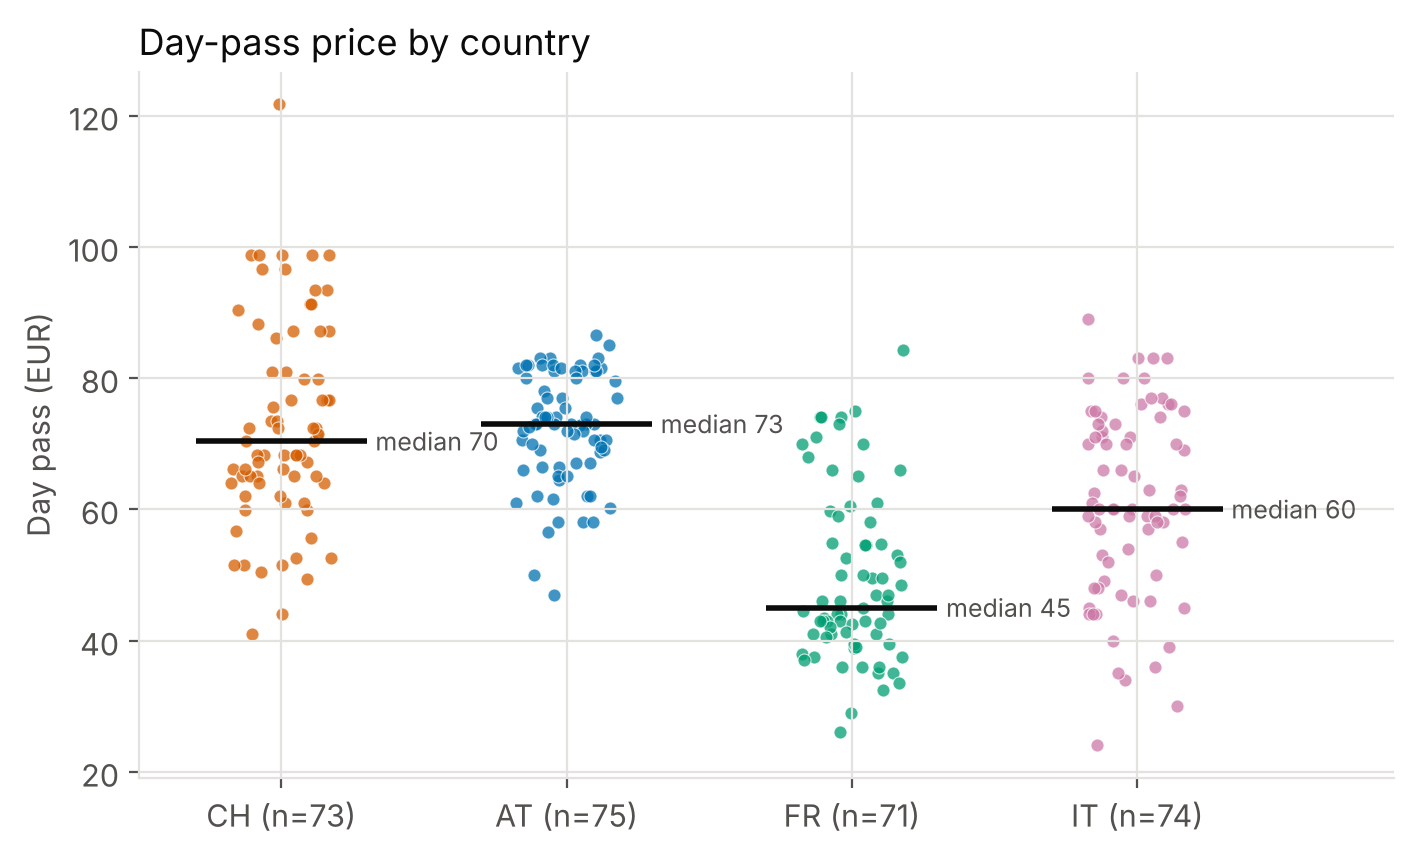

In [10]:
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(7.2, 4.4))
for i, c in enumerate(ORDER):
    y = df.loc[df["country"] == c, "price_day_eur"].to_numpy()
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(y)), y, s=22, color=COUNTRY_COLOR[c], alpha=0.75, edgecolor="white", linewidth=0.4)
    ax.hlines(np.median(y), i - 0.3, i + 0.3, color=INK, linewidth=2)
    ax.text(i + 0.33, np.median(y), f"median {np.median(y):.0f}", va="center", fontsize=9, color=INK_SOFT)
ax.set_xticks(range(4), labels=[f"{c} (n={int((df['country']==c).sum())})" for c in ORDER])
ax.set_xlim(-0.5, 3.9)
ax.set_ylabel("Day pass (EUR)")
ax.set_title("Day-pass price by country", loc="left", fontsize=13, color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_price_by_country_points.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.3 Price against resort features

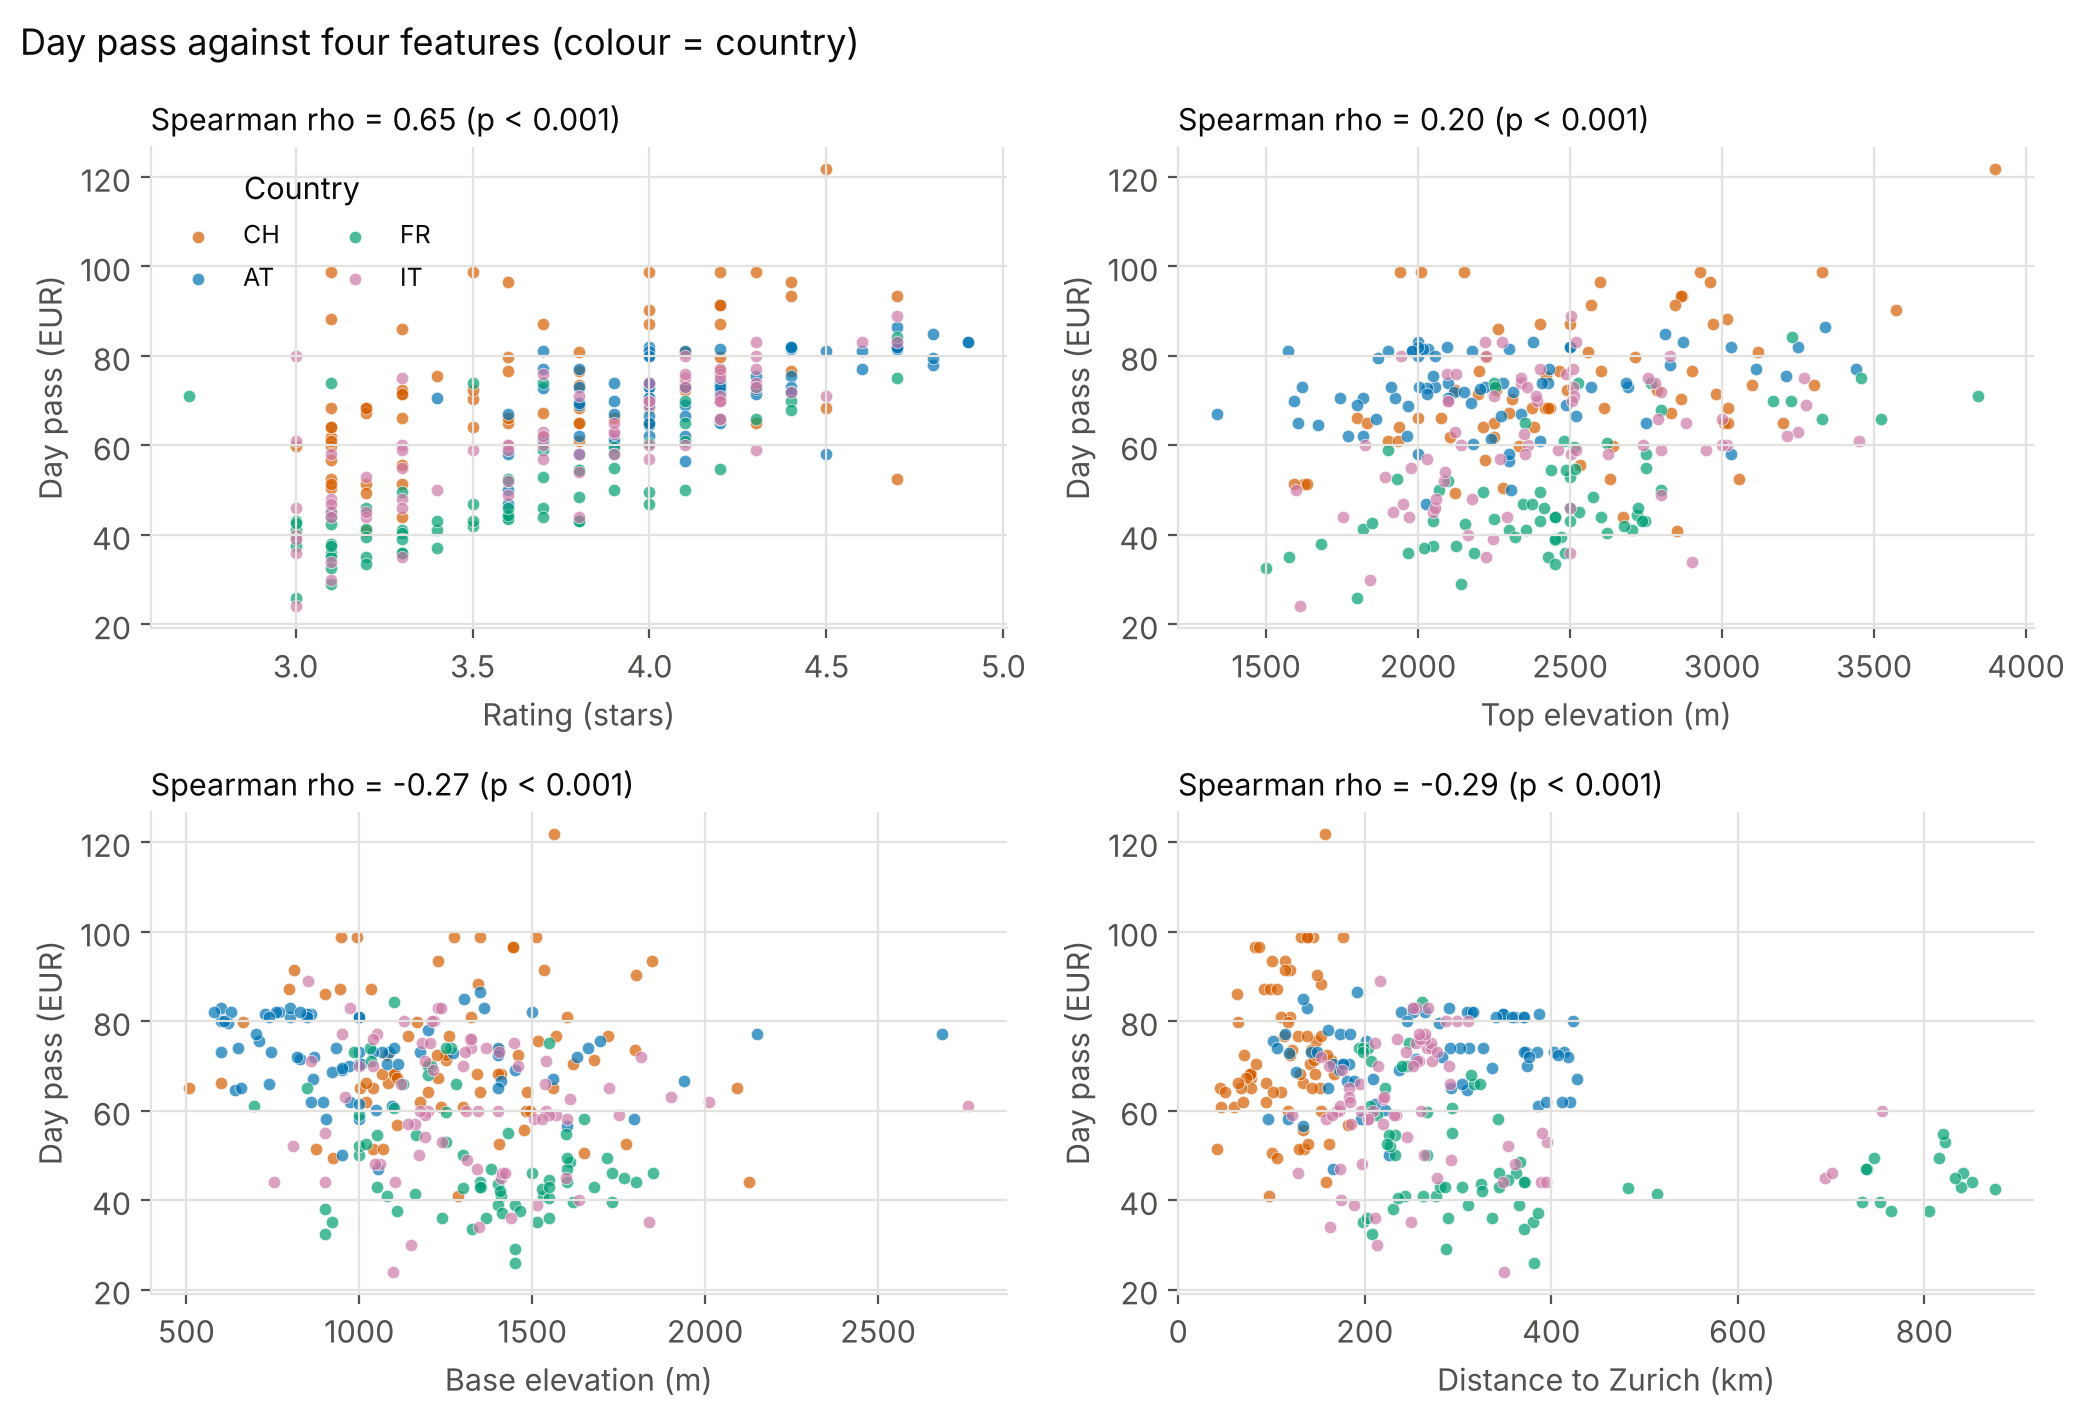

In [11]:
pairs = [("rating_stars", "Rating (stars)"), ("elevation_top_m", "Top elevation (m)"),
         ("elevation_base_m", "Base elevation (m)"), ("dist_zurich_km", "Distance to Zurich (km)")]
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.2))
for ax, (col, label) in zip(axes.ravel(), pairs):
    for c in ORDER:
        m = df["country"] == c
        ax.scatter(df.loc[m, col], df.loc[m, "price_day_eur"], s=20, color=COUNTRY_COLOR[c], alpha=0.7, edgecolor="white", linewidth=0.3, label=c)
    rho, p = stats.spearmanr(df[col], df["price_day_eur"])
    ax.set_xlabel(label); ax.set_ylabel("Day pass (EUR)")
    ax.set_title(f"Spearman rho = {rho:.2f} (p {'< 0.001' if p < 0.001 else '= ' + format(p, '.3f')})", loc="left", fontsize=11, color=INK)
axes[0, 0].legend(title="Country", frameon=False, ncol=2, fontsize=9)
fig.suptitle("Day pass against four features (colour = country)", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_price_vs_features.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the graphs.** The rating has the strongest rank relation with the price (rho = 0.65), but it is an editorial score of the website in steps of 0.1 and partly measures the quality that a high price pays for; it is a *prestige* variable, not an independent cause. Top elevation has a weak positive relation (rho = 0.20), base elevation a negative one (rho = −0.27). The negative relation with the distance to Zurich (rho = −0.29) is mainly a **country effect**: the French resorts far away (700 to 900 km) are the cheap Pyrenees resorts, and within a country the cloud of points is flat. Colours also show that Swiss prices have the widest spread, that Austrian prices form a plateau around 80 EUR, and that French prices sit below the others at every rating level. These patterns were not planned and are the reason to keep the country (or the PLI) in the price model.

### 4.4 Map: where are the ski areas and what do they cost?

Longitude and latitude on a plain grid (no map tiles needed). Dot size = top elevation, colour = price. A ring marks the areas that are **not** in the Alpine analysis set (Pyrenees, Massif Central, Apennines, Jura, Bohemian Forest). The interactive map with the closed facilities is in `docs/ski_resorts_closures_map.html`.

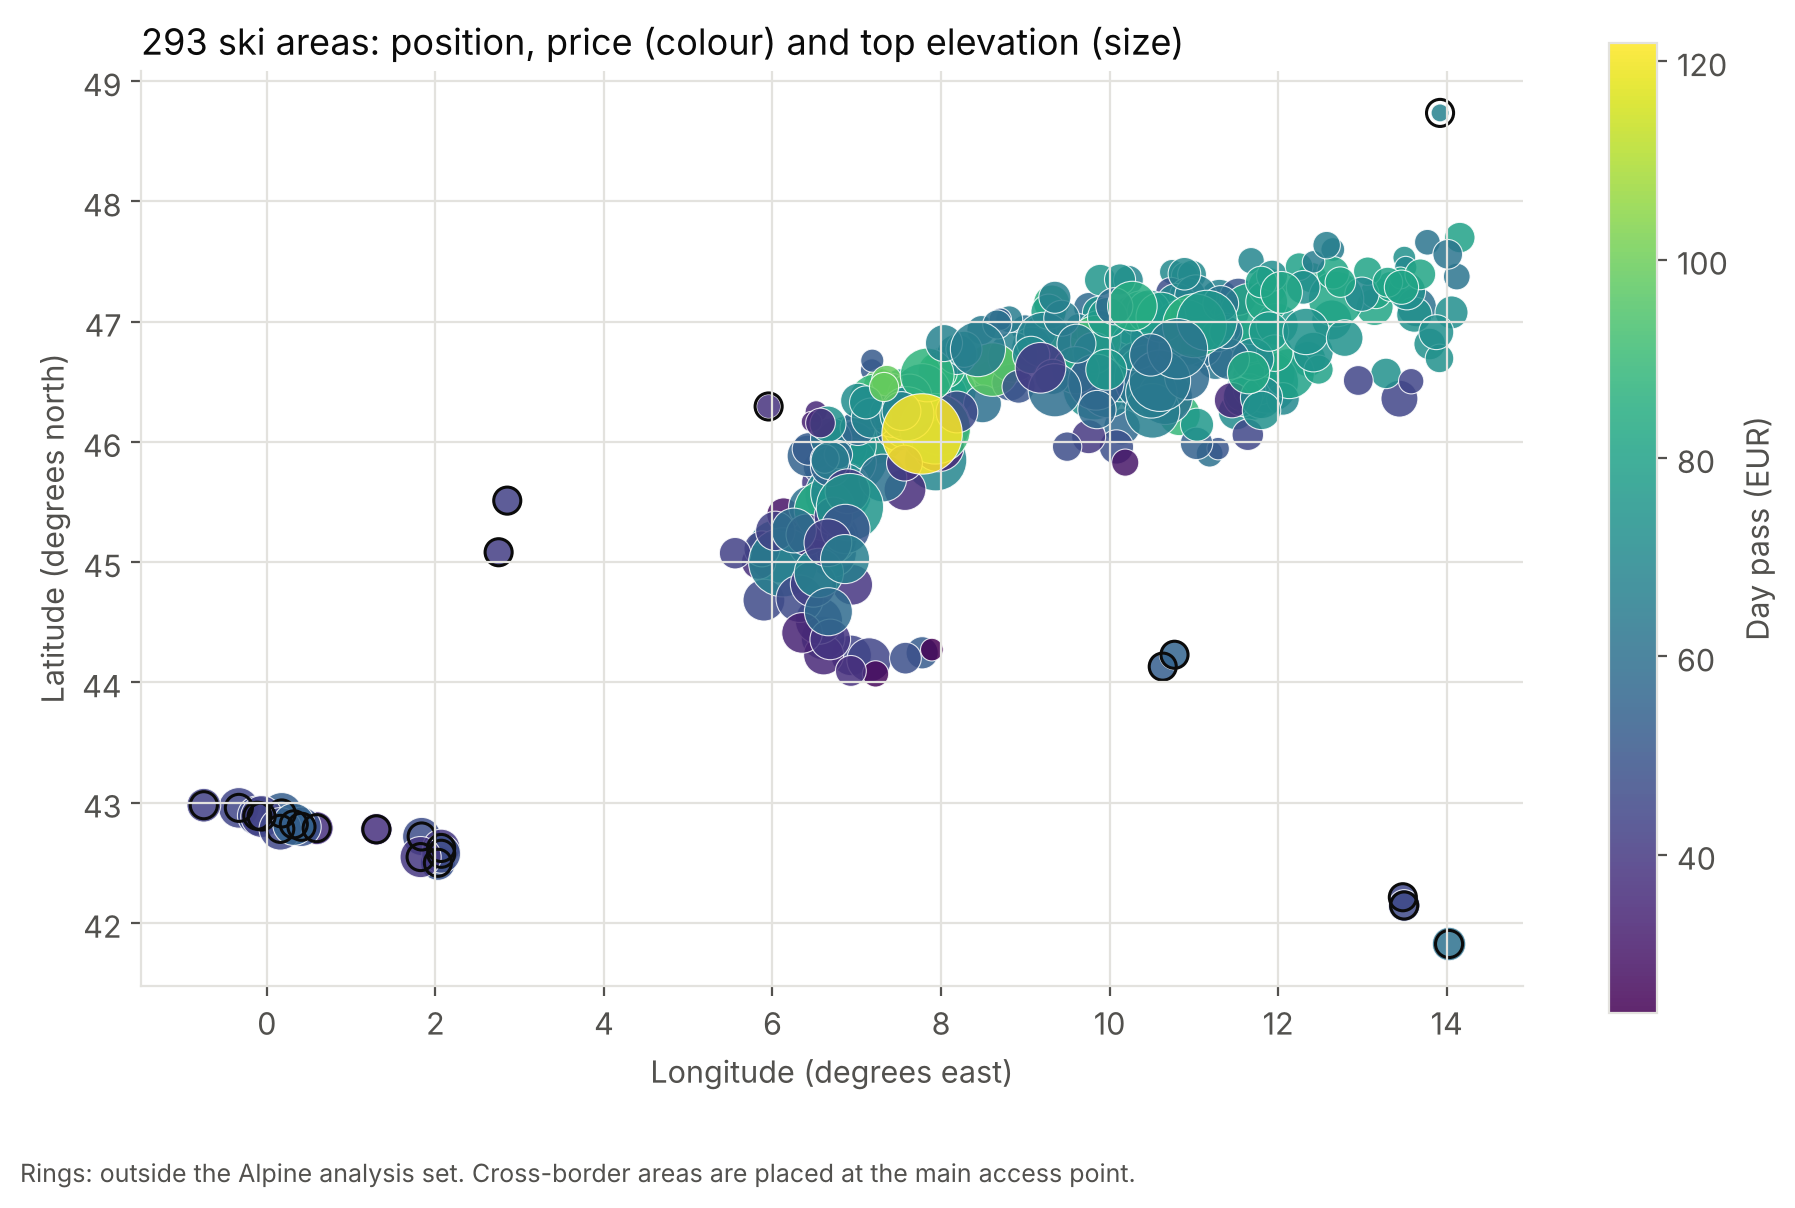

In [12]:
fig, ax = plt.subplots(figsize=(9.5, 6.4))
sc = ax.scatter(df["longitude"], df["latitude"], c=df["price_day_eur"], s=(df["elevation_top_m"] / 1000) ** 3 * 14 + 8,
                cmap="viridis", alpha=0.85, edgecolor="white", linewidth=0.4)
out = df[df["in_alpine_analysis_set"] == 0]
ax.scatter(out["longitude"], out["latitude"], s=95, facecolors="none", edgecolors=INK, linewidth=1.1)
ax.set_xlabel("Longitude (degrees east)"); ax.set_ylabel("Latitude (degrees north)")
ax.set_aspect(1 / np.cos(np.radians(45.5)))
cb = fig.colorbar(sc, ax=ax, shrink=0.8); cb.set_label("Day pass (EUR)")
ax.set_title("293 ski areas: position, price (colour) and top elevation (size)", loc="left", fontsize=13, color=INK)
fig.text(0.01, -0.01, "Rings: outside the Alpine analysis set. Cross-border areas are placed at the main access point.", fontsize=9, color=INK_SOFT)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_map_price.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the map.** The areas form the Alpine arc from the French Alps (6 to 7 °E) to Styria and Lower Austria (about 15 °E). The 24 ringed areas are outside the Alps: 15 in the Pyrenees and the Massif Central (south-west), 3 in the Apennines (south-east) and 6 that were flagged for review (Hochficht in the Bohemian Forest, Abetone and Cimone in the Apennines, Lelex-Crozet in the Jura, Saint-Lary-Soulan and Font-Romeu in the Pyrenees). The highest prices (yellow and green) are in the Valais and Bernese Oberland (about 7.5 to 8.5 °E) and in Tyrol; the cheapest (dark) are in the French and Italian south-western Alps and the Pyrenees. The positions of about 20 areas had to be corrected by hand (notebook 02.4); without that correction the map would show resorts in Zurich, Provence and Lower Austria.

### 4.5 Correlation heat map (Spearman, verified numeric columns only)

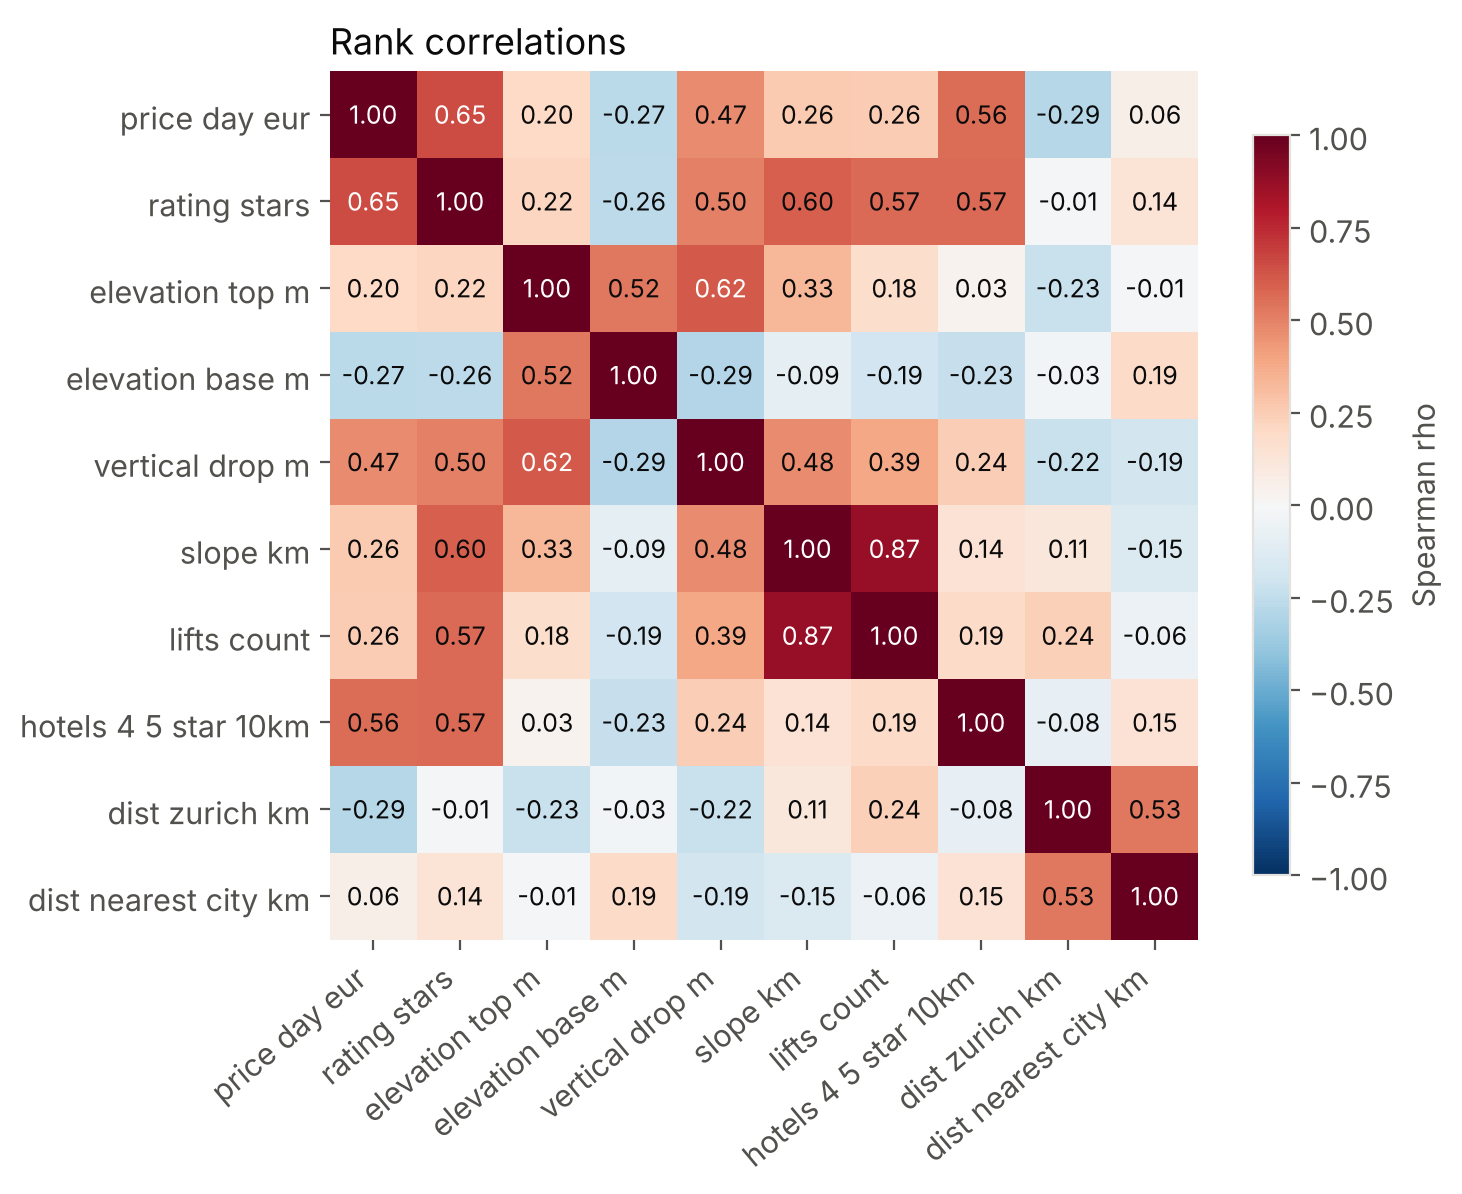

In [13]:
cols = ["price_day_eur", "rating_stars", "elevation_top_m", "elevation_base_m", "vertical_drop_m", "slope_km", "lifts_count", "hotels_4_5_star_10km", "dist_zurich_km", "dist_nearest_city_km"]
heat = df.copy()
heat.loc[heat["slope_status"] != "reparsed", "slope_km"] = np.nan   # an unverified slope length is not used
rho = heat[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.4, 6.2))
im = ax.imshow(rho.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), labels=[c.replace("_", " ") for c in cols], rotation=40, ha="right")
ax.set_yticks(range(len(cols)), labels=[c.replace("_", " ") for c in cols])
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{rho.values[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(rho.values[i, j]) > 0.6 else INK)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman rho")
ax.set_title("Rank correlations", loc="left", fontsize=13, color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the heat map.** The vertical drop (top minus base elevation) is related to the price (rho = 0.47) and to the rating (rho = 0.50). The strongest relations with the price are the rating (0.65) and the 4–5 star hotels within 10 km (0.56, a lower bound); the slope length and the number of lifts are weaker (both 0.26). Slope length and number of lifts are almost the same information (rho = 0.87), so they must not be used as two independent predictors without checking collinearity; both are also strongly tied to the rating (0.60 and 0.57), which suggests that the rating partly reflects the size of the area. The top and the base elevation are correlated with each other (0.52), which matters for a regression (collinearity); the vertical drop is partly a combination of both. The distance to Zurich is related to the price (−0.29, mainly a country effect, see above); the distance to the nearest feeder city only weakly (0.06). The two distances are related to each other (0.53).

## 5. Data provenance and quality

### 5.1 What was wrong with the size columns, and what is verified now?

`slope_km`: the old scraper read the first number after "km" on the page, which for many areas is the length of the **ski routes**, not of the slopes (Ischgl 239 km, Sölden 144.1 km and Zermatt 322 km are the page values). The pages were parsed again (`src/reparse_skiresort.py`), which also gives the number of lifts. `hotels_4_5_star_10km` was first a formula of slope length and price (not a measurement) and was replaced by a count of OpenStreetMap hotels with 4 or 5 stars within 10 km (`src/fetch_hotels_overpass.py`). The table below shows what a user of the data should know.

In [14]:
quality = pd.DataFrame([
    {"column": "price_day_eur", "status": "scraped for 291 areas; typed by hand for 2 (price_source)", "use": "yes"},
    {"column": "rating_stars, elevation_*", "status": "scraped from the same page", "use": "yes"},
    {"column": "latitude, longitude, dist_*", "status": "33 checked on the source page, 20 corrected by hand, 226 name-based geocoding only (see coordinate_check)", "use": "yes, with the limit stated in the text"},
    {"column": "slope_km", "status": ", ".join(f"{k}: {v}" for k, v in df["slope_status"].value_counts().items()), "use": "yes, except " + str(int((df["slope_status"] != "reparsed").sum())) + " area(s) with an unverified value"},
    {"column": "lifts_count", "status": f"{int(df['lifts_count'].isna().sum())} missing", "use": "yes" if df["lifts_count"].isna().sum() <= 20 else "no, too many missing"},
    {"column": "hotels_4_5_star_10km", "status": ", ".join(f"{k}: {v}" for k, v in df["hotels_status"].value_counts().items()), "use": "yes, as a lower bound" if (df["hotels_status"] == "openstreetmap_overpass").all() else "no, not counted"},
])
quality

,column,status,use
0,price_day_eur,scraped for 291 areas; typed by hand for 2 (pr...,yes
1,"rating_stars, elevation_*",scraped from the same page,yes
2,"latitude, longitude, dist_*","33 checked on the source page, 20 corrected by...","yes, with the limit stated in the text"
3,slope_km,"reparsed: 292, unverified_old_parser: 1","yes, except 1 area(s) with an unverified value"
4,lifts_count,1 missing,yes
5,hotels_4_5_star_10km,openstreetmap_overpass: 293,"yes, as a lower bound"


In [15]:
# Coordinates: how sure are we about the positions?
pos = df["coordinate_check"].value_counts().rename("n_areas").to_frame()
pos["share_pct"] = (100 * pos["n_areas"] / len(df)).round(1)
pos

,n_areas,share_pct
coordinate_check,,
verified_access_point,285,97.3
access_point_within_7km_review,8,2.7


### 5.2 Exchange rate: how much does the CHF conversion matter?

The file converts CHF to EUR with the fixed factor 1.05. With the average of the Frankfurter series for 2025 (about 1.067 EUR per CHF) the Swiss prices would be about 1.6 % higher. The check below shows what that does to the Swiss average.

In [16]:
con = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True)
chf_per_eur = pd.read_sql_query("SELECT AVG(eur_chf) AS r FROM fx_eur_chf_daily WHERE date >= '2025-01-01'", con)["r"].iloc[0]
con.close()
chf = df[df["currency"] == "CHF"]
fx_check = pd.DataFrame({
    "n_swiss_prices": [len(chf)],
    "mean_eur_fixed_1_05": [chf["price_day_eur"].mean()],
    "mean_eur_2025_average": [(chf["price_day_raw"] / chf_per_eur).mean()],
})
fx_check["difference_eur"] = fx_check["mean_eur_2025_average"] - fx_check["mean_eur_fixed_1_05"]
fx_check.round(2)

,n_swiss_prices,mean_eur_fixed_1_05,mean_eur_2025_average,difference_eur
0,73,72.74,73.93,1.19


**Reading the quality tables.** Prices, ratings and elevations are fit for analysis. The **positions** were the weakest column, so all 293 were checked against the access points listed on the source pages (`src/verify_resort_coordinates.py`): 282 are within 5 km of a listed access point, 8 lie 5–7 km away and are marked `access_point_within_7km_review` (large areas where the village and the lift access are far apart; to be glanced at on a map), and 3 positions that were wrong by more than 7 km (Hoch-Ybrig 43 km, Sonnenkopf 15 km, Pizol 8 km) were replaced by the first listed access point. Two cross-border areas are listed under a different country on the source breadcrumb (Fellhorn/Kanzelwand and Kanin/Sella Nevea/Bovec) and need a group decision. The exchange-rate choice changes the mean of the 73 Swiss prices by about 1.2 EUR (1.6 %), which is small compared with the 11 EUR gap between countries, but the group should state one rate in the report.

**What EDA tells the next step.** (1) Country must be controlled in a price model, because it explains about a third of the variation (notebook 05.3). (2) The size variables slope length, lifts and vertical drop are verified, but they are strongly related to each other and to the rating, so the models must handle collinearity. (3) The distances need a transformation or a restriction to the Alpine set, because of the Pyrenees resorts. (4) One area (Aiguille du Midi) has no verified slope length and no lift count and is left out of the models in notebook 07; the hotel count is a lower bound.

## 6. Checks

In [17]:
# 1) One row per ski area, price in a plausible range, no missing price
assert df["resort_id"].is_unique and len(df) == 293
assert df["price_day_eur"].notna().all() and df["price_day_eur"].between(10, 200).all()

# 2) Status columns agree with data_status.json
assert sorted(df["slope_status"].unique().tolist()) == status["slope_status"]
assert sorted(df["hotels_status"].unique().tolist()) == status["hotels_status"]

# 3) Descriptive statistics recomputed in a second way
assert np.isclose(by_country.loc["CH", "mean"], df.loc[df["country"] == "CH", "price_day_eur"].sum() / (df["country"] == "CH").sum(), atol=0.06)
assert abs(df["price_day_eur"].skew() - desc.loc["price_day_eur", "skewness"]) < 1e-9

# 4) The Swiss CHF prices: fixed conversion = raw x 1.05 (rounded)
assert np.allclose(chf["price_day_eur"], chf["price_day_raw"] * 1.05, atol=0.011)

# 5) Every figure was written
for f in ["eda_price_distribution", "eda_price_by_country_points", "eda_price_vs_features", "eda_map_price", "eda_correlation_heatmap"]:
    assert (FIG_DIR / f"{f}.png").exists(), f

print("All checks passed.")

All checks passed.
